In [2]:
import DataGen as dtg
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from tqdm.auto import tqdm
from efficient_kan.kan import KAN
from torch.utils.data import TensorDataset, DataLoader, Sampler

import torch.optim as optim
from architecture import Architecture
from metrics import score
SEED = 42

c:\Users\2052180\AppData\Local\miniconda3\envs\pikan\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using '{DEVICE}' device.")

Using 'cpu' device.


## Obtenção do conjunto de dados

### Definindo o espaço de velocidade


In [10]:
X_POINTS = 50
Z_POINTS = 50
Y_POINTS = 1

X_DISTANCE = 1
Y_DISTANCE = 1
Z_DISTANCE = 1


In [12]:
dg_over = 1
xover = np.arange(0, X_POINTS, dg_over)
zover = np.arange(0, Z_POINTS, dg_over)

v_line_z = 1.5 + zover
v_line_x = np.tile(0.3 * xover, (len(zover), 1))
v_depth = np.tile(v_line_z[:, np.newaxis], (1, len(xover))) + v_line_x

v_depth = v_depth.reshape(X_POINTS,Z_POINTS,Y_POINTS) # necessário adicionar a terceira dimensão para o modelo do Solver

In [6]:
# dg_over = 0.1
# xover = np.arange(0, 3, dg_over)
# zover = np.arange(0, 3, dg_over)

# v_line_z = 1.5 + zover
# v_line_x = np.tile(0.3 * xover, (len(zover), 1))
# v_depth = np.tile(v_line_z[:, np.newaxis], (1, len(xover))) + v_line_x

# v_depth = v_depth.reshape(X_POINTS,Z_POINTS,Y_POINTS) # necessário adicionar a terceira dimensão para o modelo do Solver

In [19]:
df = dtg.generateMultipleData(
    nPoints = (X_POINTS, Z_POINTS, Y_POINTS), 
    nodeDistances = (X_DISTANCE, Y_DISTANCE, Z_DISTANCE),
    velocityModel = v_depth,
    sourceOriginInterval= [[5,5],[6,6]])

In [8]:
df.head(10)

,x,z,travel_time,source_x0,source_z0
0,0,0,1.887642,5,5
1,0,1,1.623350,5,5
2,0,2,1.408306,5,5
3,0,3,1.236464,5,5
4,0,4,1.103410,5,5
5,0,5,1.015035,5,5
6,0,6,1.011127,5,5
7,0,7,1.025442,5,5
8,0,8,1.057046,5,5
9,0,9,1.103390,5,5


In [ ]:
new_df = dtg.check_derivatives(df)
new_df


In [14]:
features = ['x', 'z', 'source_x0', 'source_z0']
target = ['travel_time']

### Separando o conjunto em Treinamento, Validação e Teste

In [20]:
initial_conditions = df[['source_x0', 'source_z0']].drop_duplicates().reset_index(drop=True)
aux = initial_conditions.copy()

ic_train = aux.sample(frac=0.6, random_state=SEED)
ic_val = aux.drop(ic_train.index).sample(frac=0.5, random_state=SEED)
ic_test = aux.drop(list(ic_train.index) + list(ic_val.index))

print("Train Initial Conditions:", len(ic_train))
print("Validation Initial Conditions:", len(ic_val))
print("Test Initial Conditions:", len(ic_test))

Train Initial Conditions: 2
Validation Initial Conditions: 1
Test Initial Conditions: 1


In [21]:
df_train = df.merge(ic_train, on=['source_x0', 'source_z0'], how='inner')
df_val = df.merge(ic_val, on=['source_x0', 'source_z0'], how='inner')
df_test = df.merge(ic_test, on=['source_x0', 'source_z0'], how='inner')

print("Train Size:", len(df_train))
print("Validation Size:", len(df_val))
print("Test Size:", len(df_test))

Train Size: 5000
Validation Size: 2500
Test Size: 2500


In [11]:
from itertools import cycle
import random


class BalancedBatchSampler(Sampler):
    def __init__(self, dataset, batch_size, t_index=3, shuffle=True):
        """
    A sampler that generates balanced batches from a dataset, ensuring that each batch contains
    an equal number of samples with a specific target value.
    Args:
        dataset (Dataset): The dataset to sample from.
        batch_size (int): The number of samples per batch.
        t_index (int, optional): The index of the target value in the dataset samples. Default is 4.
        shuffle (bool, optional): Whether to shuffle the batch indices. Default is True.
        
    Attributes:
        dataset (Dataset): The dataset to sample from.
        batch_size (int): The number of samples per batch.
        t_index (int): The index of the target value in the dataset samples.
        shuffle (bool): Whether to shuffle the batch indices.
        t_zero_indices (list): Indices of samples with target value equal to 0.
        non_t_zero_indices (list): Indices of samples with target value not equal to 0.
        
    Methods:
        __iter__(): Generates balanced batches of indices.
        __len__(): Returns the number of batches.
    """
        if batch_size % 2 != 0 or batch_size <= 0:
            raise ValueError("batch_size deve ser um número inteiro positivo e par.")
        
        self.dataset = dataset
        self.batch_size = batch_size
        self.t_index = t_index
        self.shuffle = shuffle

        # Dividir o dataset em duas partes: com t=0 e sem t=0
        self.t_zero_indices = []
        self.non_t_zero_indices = []

        for i in range(len(self.dataset)):
            data = self.dataset[i]
            try:
                t_sample = data[0][self.t_index]
            except (IndexError, TypeError):
                raise ValueError(f"O índice de tempo t_index={self.t_index} não é válido.")
            if t_sample == 0:
                self.t_zero_indices.append(i)
            else:
                self.non_t_zero_indices.append(i)

        if not self.t_zero_indices or not self.non_t_zero_indices:
            raise ValueError("Não há amostras suficientes em cada classe para criar batches balanceados.")

    def __iter__(self):
        if self.shuffle:
            random.shuffle(self.t_zero_indices)
            random.shuffle(self.non_t_zero_indices)

        t_zero_iter = cycle(self.t_zero_indices)
        non_t_zero_iter = cycle(self.non_t_zero_indices)

        num_batches = len(self.dataset) // self.batch_size

        for _ in range(num_batches):
            t_zero_batch = [next(t_zero_iter) for _ in range(2)] # Samples with t=0 per batch
            non_t_zero_batch = [next(non_t_zero_iter) for _ in range(self.batch_size-2)]
            batch_indices = t_zero_batch + non_t_zero_batch

            if self.shuffle:
                random.shuffle(batch_indices)

            yield batch_indices

    def __len__(self):
        return len(self.dataset) // self.batch_size

In [22]:
#SOURCE BALANCED BATCH SAMPLER
from torch.utils.data import Sampler
from collections import defaultdict
import random
from itertools import cycle, islice

class SourceBalancedBatchSampler(Sampler):
    def __init__(self, dataset, batch_size, source_x_index=2, source_z_index=3, shuffle=True):
        """
        Sampler que cria batches balanceados por origem da fonte (source_x0, source_z0).
        """
        if batch_size <= 0:
            raise ValueError("batch_size deve ser um número inteiro positivo.")

        self.dataset = dataset
        self.batch_size = batch_size
        self.source_x_index = source_x_index
        self.source_z_index = source_z_index
        self.shuffle = shuffle

        # Agrupar índices por (source_x0, source_z0)
        self.source_groups = defaultdict(list)

        for i in range(len(self.dataset)):
            data = self.dataset[i]
            try:
                source_x = data[0][self.source_x_index]
                source_z = data[0][self.source_z_index]
            except (IndexError, TypeError):
                raise ValueError(f"Índices source_x_index={self.source_x_index}, source_z_index={self.source_z_index} não são válidos.")

            self.source_groups[(source_x, source_z)].append(i)

        if len(self.source_groups) < 2:
            raise ValueError("São necessárias pelo menos duas fontes diferentes para balancear os batches.")

        self.sources = list(self.source_groups.keys())

    def __iter__(self):
        # Cria iteradores infinitos para cada grupo de fonte
        iterators = {src: cycle(indices) for src, indices in self.source_groups.items()}

        # Define quantos grupos de fonte por batch
        num_sources = len(self.sources)
        samples_per_source = self.batch_size // num_sources
        remainder = self.batch_size % num_sources

        if self.shuffle:
            random.shuffle(self.sources)

        num_batches = len(self.dataset) // self.batch_size

        for _ in range(num_batches):
            batch_indices = []

            # Coletar amostras balanceadas de cada fonte
            for src in self.sources:
                batch_indices += list(islice(iterators[src], samples_per_source))

            # Se o batch não for divisível perfeitamente, preenche com mais amostras aleatórias
            if remainder > 0:
                extra_srcs = random.sample(self.sources, remainder)
                for src in extra_srcs:
                    batch_indices.append(next(iterators[src]))

            if self.shuffle:
                random.shuffle(batch_indices)

            yield batch_indices

    def __len__(self):
        return len(self.dataset) // self.batch_size

In [23]:
# Convertendo os dados para tensores
X_train = torch.as_tensor(df_train[features].values, dtype=torch.float32)
y_train = torch.as_tensor(df_train[target].values, dtype=torch.float32)

X_val = torch.as_tensor(df_val[features].values, dtype=torch.float32)
y_val = torch.as_tensor(df_val[target].values, dtype=torch.float32)

X_test = torch.as_tensor(df_test[features].values, dtype=torch.float32)
y_test = torch.as_tensor(df_test[target].values, dtype=torch.float32)

# Criando o Dataset
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

# Criando um loader para cada conjunto de dados
sampler = SourceBalancedBatchSampler(train_dataset, batch_size=256)
train_loader = DataLoader(dataset=train_dataset,
                          batch_sampler=sampler,
                        #   shuffle=False,
                        #   batch_size=256,
                          )

val_loader = DataLoader(dataset=val_dataset,
                        shuffle=False,
                        batch_size=256
                        )

test_loader = DataLoader(dataset=test_dataset,
                        shuffle=False,
                        batch_size=len(test_dataset)
                        )

In [59]:
# Função de perda física ajustada
def physics_loss_fn(model, input_tensor, *args, **kwargs):
    # Separe as entradas e garanta que as variáveis requerem gradiente
    x = input_tensor[:, 0].view(-1, 1)  # x0
    z = input_tensor[:, 1].view(-1, 1)  # z0
    source_x0 = input_tensor[:, 2].view(-1, 1)  # theta0
    source_z0 = input_tensor[:, 3].view(-1, 1)  # t

    # Certifique-se de que todas as variáveis tenham requires_grad=True para calcular derivadas
    x.requires_grad_(True)
    z.requires_grad_(True)
    source_x0.requires_grad_(True)
    source_z0.requires_grad_(True)
    

    # Recalcule yhat usando as variáveis para garantir a conexão
    x_reconstructed = torch.cat([x, z, source_x0, source_z0], dim=1)
    yhat = model(x_reconstructed)
    
    travel_t = yhat[:, 0].view(-1, 1)

    # Calcule v(x, z)
    v = 1.5 + 0.3*z + x
    
    # Calcule os gradientes necessários (dt/dx, dt/dz)
    dtdx = torch.autograd.grad(
        outputs=travel_t,  # Derivada de t em relação a x
        inputs=x,
        grad_outputs=torch.ones_like(x),
        create_graph=True,
        retain_graph=True
    )[0]

    dtdz = torch.autograd.grad(
        outputs=travel_t,  # Derivada de t em relação a z
        inputs=z,
        grad_outputs=torch.ones_like(z),
        create_graph=True,
        retain_graph=True
    )[0]


    ## (dt/dx)**2 + (dt/dz)**2 - (1/v)**2
    pde1 = dtdx**2 + dtdz**2 - (1/v)**2

    # Calcular a perda como a soma dos erros quadrados das PDEs
    loss = torch.mean(pde1 ** 2)

    return loss

In [24]:
def physics_loss_fn(model, input_tensor, *args, **kwargs):
    x = input_tensor[:, 0].view(-1, 1)
    z = input_tensor[:, 1].view(-1, 1)
    source_x0 = input_tensor[:, 2].view(-1, 1)
    source_z0 = input_tensor[:, 3].view(-1, 1)

    # Concatenação e ativação do autograd
    coords = torch.cat([x, z], dim=1)
    coords.requires_grad_(True)
    source_x0.requires_grad_(True)
    source_z0.requires_grad_(True)

    inputs = torch.cat([coords, source_x0, source_z0], dim=1)
    travel_t = model(inputs)

    v = 1.5 + 0.3 * coords[:, 1:2] + coords[:, 0:1]

    grads = torch.autograd.grad(
        outputs=travel_t,
        inputs=coords,
        grad_outputs=torch.ones_like(travel_t),
        create_graph=True
    )[0]

    dtdx = grads[:, 0:1]
    dtdz = grads[:, 1:2]

    pde = dtdx**2 + dtdz**2 - (1 / v)**2
    loss = torch.mean(pde**2)

    return loss

In [25]:
def sin():
    return torch.sin

In [26]:
torch.manual_seed(42)
input_size = len(features)
output_size = len(target)
model = KAN([input_size, 8, 6, 4, 2, output_size], grid_size=12,
            spline_order=3, base_activation=sin)

# Defines optimizer to update the parameters
optimizer = optim.Adam(model.parameters(),
                        lr=1e-3)


# Defines a MSE loss function
loss_fn = torch.nn.MSELoss(reduction='mean')

In [27]:
arch = Architecture(model, loss_fn, physics_loss_fn,
                    optimizer, lamb=0, lamb_l1=0,
                    lamb_entropy=0, lambda_physics=1e-2)
arch.set_loaders(train_loader, val_loader)

In [35]:
n_epochs = 100
arch.train(n_epochs=n_epochs, seed=SEED)

Training PIKAN: 100%|██████████| 180/180 [01:40<00:00,  1.01s/it, data_loss=0.19, loss=0.191, physics_loss=0.00111, val_loss=0.256]  


In [26]:
arch.save_checkpoint(f"output/checkpoint_{n_epochs}epochs.pt")

C:\Users\2052180\AppData\Local\Temp\ipykernel_19144\4065197815.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


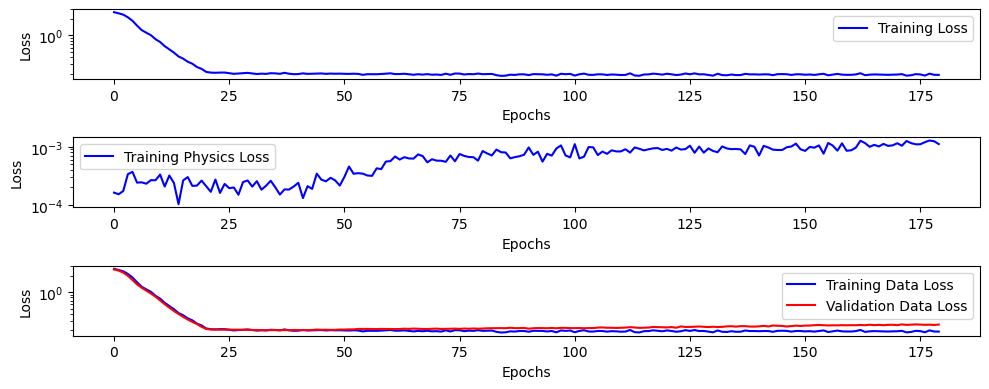

In [36]:
fig = arch.plot_losses()
fig.show()

In [32]:
predictions = arch.predict(df_test[features].values)
df_pred = pd.DataFrame(predictions, columns=target)
df_pred = df_test[features].join(df_pred)
df_pred.head()

,x,z,source_x0,source_z0,travel_time
0,0,0,5,5,1.694243
1,0,1,5,5,1.688424
2,0,2,5,5,1.789624
3,0,3,5,5,1.786860
4,0,4,5,5,1.786867


In [33]:
df_filtrado = df[(df['source_x0'] == 5) & (df['source_z0'] == 5)]
print(df_filtrado)

       x   z  travel_time  source_x0  source_z0
0      0   0     1.887642          5          5
1      0   1     1.623350          5          5
2      0   2     1.408306          5          5
3      0   3     1.236464          5          5
4      0   4     1.103410          5          5
...   ..  ..          ...        ...        ...
2495  49  45     2.164063          5          5
2496  49  46     2.177999          5          5
2497  49  47     2.192024          5          5
2498  49  48     2.206129          5          5
2499  49  49     2.220302          5          5

[2500 rows x 5 columns]


In [34]:
score(df_pred[target].values, df_test[target].values, ["travel_time"])

,travel_time
R²,0.028545
MAPE,inf
MAE,0.361598
MSE,0.211641
RMSE,0.460045


## Testando com MLP

In [44]:
class MLP(torch.nn.Module):
    def __init__(self, input_dim=4, hidden_dim=64, output_dim=1):
        super(MLP, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.net(x)

In [45]:
epochs = 10000

In [46]:
model = MLP()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(epochs):
    model.train()
    
    X_train = torch.as_tensor(df_train[features].values, dtype=torch.float32)
    y_train = torch.as_tensor(df_train[target].values, dtype=torch.float32) 
    
    preds = model(X_train)
    
    # Data loss (MSE)
    data_loss = nn.MSELoss()(preds, y_train)
    
    # Physics loss
    phys_loss = physics_loss_fn(model, X_train)
    
    # Loss total com pesos (ex: balanceamento)
    loss = data_loss + 1.0 * phys_loss
    
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

In [54]:
phys_loss

tensor(9.1046e-07, grad_fn=<MeanBackward0>)

In [52]:
model.eval()
predictions = model(X_val)
print(predictions)

tensor([[2.0314],
        [1.7704],
        [1.5736],
        ...,
        [2.1203],
        [2.1347],
        [2.1495]], grad_fn=<AddmmBackward0>)


In [53]:
y_val

tensor([[1.9450],
        [1.6954],
        [1.4960],
        ...,
        [2.0824],
        [2.0966],
        [2.1108]])